# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [ ]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")

print("Forme :", brut.shape)
print("\nTypes de colonnes :\n", brut.dtypes)
print("\nValeurs manquantes :\n", brut.isnull().sum())
print("\nLignes en double :", brut.duplicated().sum())

**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [ ]:
# Nombre d'écritures uniques dans la colonne quartier
nb_ecritures = brut['quartier'].nunique()
print("Nombre d'écritures différentes pour quartier :", nb_ecritures)
print("\nListe des valeurs uniques :\n", brut['quartier'].unique())

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [ ]:

non_convertibles = brut[pd.to_numeric(brut['kwh'], errors='coerce').isna() & brut['kwh'].notna()]['kwh'].unique()

print("Valeurs non convertibles :")
print(non_convertibles)

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [ ]:
#creation copie du dataframe brut pour nettoyage
propre = brut.copy()

propre['kwh'] = propre['kwh'].astype(str).str.replace(' kWh', '', regex=False)
propre['kwh'] = propre['kwh'].str.replace(' ', '', regex=False)
propre['kwh'] = pd.to_numeric(propre['kwh'], errors='coerce')

print("Valeurs manquantes dans kwh après conversion :", propre['kwh'].isnull().sum())

**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [ ]:
# Charger le fichier des quartiers pour récupérer les noms officiels
quartiers_df = pd.read_csv("donnees/quartiers.csv")
noms_officiels = quartiers_df['quartier'].unique()

mapping_quartiers = {q.lower().strip(): q for q in noms_officiels}

# Ajouter quelques corrections spécifiques et nettoter les espaces
propre['quartier_clean'] = propre['quartier'].astype(str).str.strip().str.lower()
propre['quartier'] = propre['quartier_clean'].map(mapping_quartiers)

propre = propre.drop(columns=['quartier_clean'])

print("Quartiers uniques après harmonisation :", propre['quartier'].nunique())
print(propre['quartier'].unique())

Quartiers uniques après harmonisation : 12
<ArrowStringArray>
[  'Bas-Peu-de-Chose',         'Bois-Verna',       'Centre-ville',
          'Delmas 33',          'Delmas 65',          'Delmas 75',
          'Thomassin', 'Place Saint-Pierre',     'Morne Calvaire',
           'Carénage',             'Rue 15',        'Petite-Anse']
Length: 12, dtype: str


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [ ]:

propre = propre.drop_duplicates()
propre = propre.dropna(subset=['kwh'])

print("Forme de propre après nettoyage :", propre.shape)

Forme de propre après nettoyage : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [ ]:
# Calculer la médiane par quartier
mediane_quartier = propre.groupby('quartier')['kwh'].transform('median')

masque = propre['kwh'] > (3 * mediane_quartier)
propre.loc[masque, 'kwh'] = propre.loc[masque, 'kwh'] / 10

print("Maximum de kwh après correction :", propre['kwh'].max())

Maximum de kwh après correction : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [ ]:

reference = pd.read_csv("donnees/consommation.csv")

cols = [c for c in propre.columns if c in reference.columns]
p_val = propre[cols].dropna().sort_values(by=['quartier', 'mois']).reset_index(drop=True)
r_val = reference[cols].dropna().sort_values(by=['quartier', 'mois']).reset_index(drop=True
print("Égalité des données nettoyées :", p_val.equals(r_val))

Égalité des données nettoyées : False


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [ ]:

quartiers = pd.read_csv("donnees/quartiers.csv")


print("Lignes avant merge :", propre.shape[0])

propre_quartiers = pd.merge(propre, quartiers, on="quartier", how="left")

print("Lignes après merge :", propre_quartiers.shape[0])
propre_quartiers['kwh_par_abonne'] = (propre_quartiers['kwh'] / propre_quartiers['abonnes']).round(1)

propre_quartiers['annee'] = propre_quartiers['mois'].astype(str).str.slice(0, 4)


test_val = propre_quartiers[(propre_quartiers['quartier'] == 'Bas-Peu-de-Chose') & (propre_quartiers['mois'] == '2024-01')]
print("\nExemple Bas-Peu-de-Chose 2024-01 :")
print(test_val[['quartier', 'mois', 'kwh_par_abonne']])

Lignes avant merge : 279
Lignes après merge : 279

Exemple Bas-Peu-de-Chose 2024-01 :
           quartier     mois  kwh_par_abonne
0  Bas-Peu-de-Chose  2024-01            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [ ]:
# Charger le fichier météo
meteo = pd.read_csv("donnees/meteo.csv")

print("Lignes avant merge météo :", propre_quartiers.shape[0])


avec_meteo = pd.merge(propre_quartiers, meteo, on=["mois", "commune"], how="left")

print("Lignes après merge météo :", avec_meteo.shape[0])

print("Températures manquantes :", avec_meteo['temperature_c'].isnull().sum())

Lignes avant merge météo : 279
Lignes après merge météo : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [ ]:

avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

df_final = pd.read_csv("donnees/consommation_propre.csv")
print("Forme du fichier final enregistré :", df_final.shape)

Forme du fichier final enregistré : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [ ]:

conso_par_type = avec_meteo.groupby('type')['kwh_par_abonne'].mean().round(1)
print("Consommation moyenne par abonné par type :\n", conso_par_type)

classement_quartiers = avec_meteo.groupby('quartier')['kwh_par_abonne'].mean().sort_values(ascending=False).round(1)
print("\nClassement des 12 quartiers :\n", classement_quartiers)

Consommation moyenne par abonné par type :
 type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers :
 quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

Consommation totale par commune et par année (en millions de kWh) :
 annee            2024   2025
commune                     
Cap-Haïtien      4.59   5.62
Delmas          11.61  11.74
Port-au-Prince  10.09  10.31
Pétion-Ville     8.60   9.68

Hausse en % :
 commune
Cap-Haïtien       22.4
Delmas             1.1
Port-au-Prince     2.2
Pétion-Ville      12.6
dtype: float64


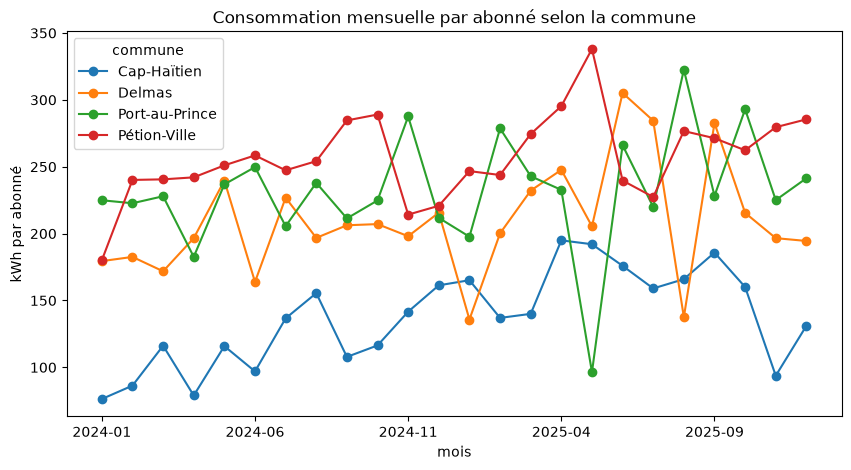

In [ ]:
import matplotlib.pyplot as plt


conso_commune_annee = avec_meteo.pivot_table(index='commune', columns='annee', values='kwh', aggfunc='sum') / 1e6
conso_commune_annee = conso_commune_annee.round(2)
print("Consommation totale par commune et par année (en millions de kWh) :\n", conso_commune_annee)

hausse_pct = ((conso_commune_annee['2025'] - conso_commune_annee['2024']) / conso_commune_annee['2024'] * 100).round(1)
print("\nHausse en % :\n", hausse_pct)

conso_mensuelle = avec_meteo.pivot_table(index='mois', columns='commune', values='kwh_par_abonne', aggfunc='mean')
conso_mensuelle.plot(figsize=(10, 5), marker='o')
plt.title("Consommation mensuelle par abonné selon la commune")
plt.ylabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


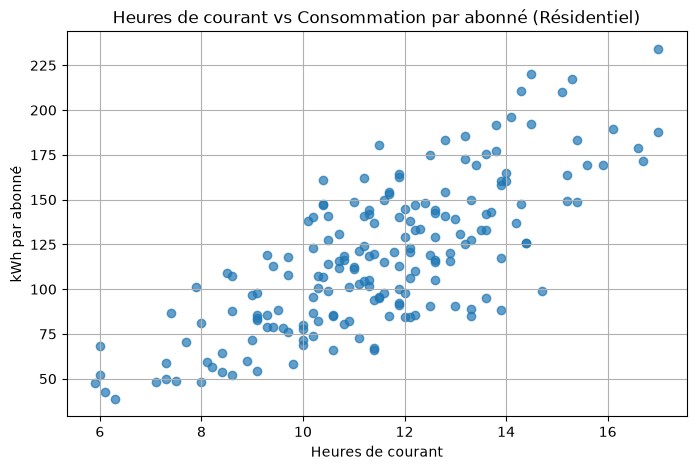

In [27]:
# Filtrer uniquement les quartiers résidentiels
residentiel = avec_meteo[avec_meteo['type'] == 'Résidentiel']

# Calcul des corrélations
corr_heures = residentiel['kwh_par_abonne'].corr(residentiel['heures_courant'])
corr_temp = residentiel['kwh_par_abonne'].corr(residentiel['temperature_c'])

print(f"Corrélation avec les heures de courant : {corr_heures:.2f}")
print(f"Corrélation avec la température : {corr_temp:.2f}")

# Nuage de points avec matplotlib pur
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(residentiel['heures_courant'], residentiel['kwh_par_abonne'], alpha=0.7)
plt.title("Heures de courant vs Consommation par abonné (Résidentiel)")
plt.xlabel("Heures de courant")
plt.ylabel("kWh par abonné")
plt.grid(True)
plt.show()

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Statistiques des heures de courant par commune :
                 mediane    Q1    Q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


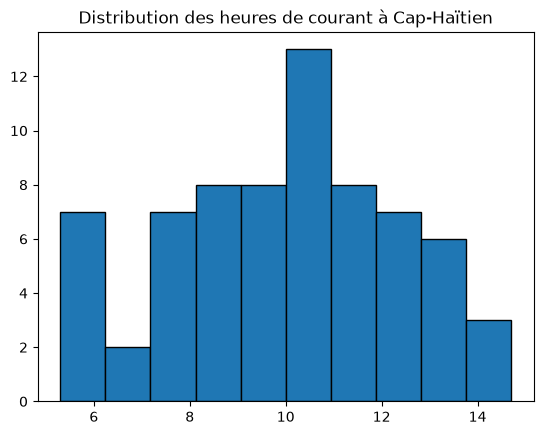


Relevés de 2025 avec moins de 8h de courant :
        mois   quartier  heures_courant
81   2025-01  Delmas 33             7.4
227  2025-08   Carénage             7.3
253  2025-11     Rue 15             5.9


In [28]:
# Médiane, Q1, Q3 par commune pour les heures de courant
stats_courant = avec_meteo.groupby('commune')['heures_courant'].agg(
    mediane=lambda x: x.quantile(0.5),
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).round(1)
print("Statistiques des heures de courant par commune :\n", stats_courant)

# Histogramme pour Cap-Haïtien
cap_haitien = avec_meteo[avec_meteo['commune'] == 'Cap-Haïtien']
plt.hist(cap_haitien['heures_courant'], bins=10, edgecolor='black')
plt.title("Distribution des heures de courant à Cap-Haïtien")
plt.show()

# Relevés de 2025 ayant moins de 8 heures de courant par jour
moins_8h = avec_meteo[(avec_meteo['annee'] == '2025') & (avec_meteo['heures_courant'] < 8)]
print("\nRelevés de 2025 avec moins de 8h de courant :")
print(moins_8h[['mois', 'quartier', 'heures_courant']])

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [ ]:

top_3 = avec_meteo.nlargest(3, 'kwh')[['mois', 'quartier', 'type', 'kwh']]
print("Les 3 plus grosses consommations :")
print(top_3)

Les 3 plus grosses consommations :
       mois      quartier        type       kwh
87  2025-07     Delmas 33  Commercial  742780.0
56  2024-11  Centre-ville  Commercial  597730.0
88  2025-09     Delmas 33  Commercial  591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.